# 03. 강건성 점검 · robustness v1.0 (원승연)

발표에서 쓴 상관 결과가 **다른 방법으로 다시 분석해도 버티는지** 확인하는 노트북입니다. 계산은 `source/robustness_check.py`의 함수를 그대로 부르므로, 이 노트북과 스크립트의 숫자는 항상 같습니다.

| 블록 | 내용 | 무엇을 보나 |
|---|---|---|
| 0 | 경로 준비 · 실행 | 프로젝트 폴더를 찾고 모든 계산을 한 번 실행 |
| ① | 상관 한 세트 | r · p값 · 95% 신뢰구간 · 순위상관 · 순열 p · 블록 부트스트랩 · BH 보정 q |
| ② | 시계열 성질 | 정상성(ADF·KPSS), 공적분, 교차상관, 그레인저 |
| ③ | 회귀 사다리 | 통제변수·국면 더미를 넣었을 때 SOFR 계수 변화 (Newey-West HAC) |
| ④ | 기여도 분해 민감도 | 분해 방식·시작 달을 바꿔도 금리 몫 72%가 유지되는지 |
| ⑤ | 다중비교 보정 | 검정 31개 전체에 BH · BY · 본페로니 |
| ⑥ | 그림 4종 · 제출본 대조 | 결과가 `output/robustness.json`과 같은지 |

**사용법**: 프로젝트 폴더의 `source/`에서 열고 **모두 실행**합니다. 결과는 `source/_run/robustness/`에 저장되고 제출 파일(`output/`)은 건드리지 않습니다. Colab은 첫 셀 안내를 따릅니다.

> 투자 권유가 아닙니다. 상관·회귀는 인과를 뜻하지 않습니다.

## 0. 경로 준비 · 실행

In [1]:
# 0. 프로젝트 폴더 찾기 (로컬: 이 노트북은 source/ 안에 있음 / Colab: ZIP을 올리면 자동으로 풂)
import sys, json, zipfile, importlib.util
from pathlib import Path

def find_root():
    for p in [Path.cwd(), Path.cwd().parent, Path("/content/MODULE04_미니프로젝트03_2조")]:
        if (p / "data/processed/monthly_analysis.csv").exists():
            return p
    return None

ROOT = find_root()
if ROOT is None and importlib.util.find_spec("google.colab") is not None:
    from google.colab import files               # Colab: 제출 ZIP을 선택해 올린다
    up = files.upload()
    zipfile.ZipFile(next(iter(up))).extractall("/content")
    ROOT = find_root()
    !pip -q install statsmodels
assert ROOT is not None, "프로젝트 폴더를 찾지 못했습니다. source/ 폴더에서 노트북을 여세요."
sys.path.insert(0, str(ROOT / "source"))
import robustness_check as rc
importlib.reload(rc)
RUN = ROOT / "source/_run/robustness"
print("프로젝트 폴더:", ROOT.name)
print("결과 저장 위치:", RUN.relative_to(ROOT))

프로젝트 폴더: MODULE04_미니프로젝트03_2조
결과 저장 위치: source/_run/robustness


In [2]:
R = rc.run_all(base=ROOT, out_dir=RUN, fig_dir=RUN / "figures")   # 약 20초 (순열 10,000회 · 부트스트랩 5,000회)

[robustness v1.0] 검정 31개 · 보정 전 유의 11개 → BH 보정 후 8개
구분                           n       r         p     BH q   95% CI         블록 부트스트랩
수준값 전체                      72  +0.801   2.9e-17 9.12e-16   +0.70~+0.87    +0.59~+0.90
변화값 전체                      71  -0.052      0.67    0.859   -0.28~+0.18    -0.34~+0.24
수준값 2020-22                 36  +0.745   1.9e-07 1.18e-06   +0.55~+0.86    +0.15~+0.92
변화값 2020-22                 35  -0.060      0.73    0.859   -0.39~+0.28    -0.22~+0.37
수준값 2023-25                 36  -0.555   0.00044  0.00195   -0.75~-0.28    -0.83~+0.21
변화값 2023-25                 36  -0.024      0.89    0.951   -0.35~+0.31    -0.42~+0.37
수준값 저금리(<0.5%)              25  +0.452     0.023   0.0807   +0.07~+0.72    -0.35~+0.75
수준값 전환기(0.5~3%)              8  +0.706      0.05     0.13   +0.00~+0.94    -0.18~+0.94
수준값 고금리(≥3%)                39  -0.402     0.011   0.0435   -0.64~-0.10    -0.81~+0.30
변화값 2020-03 제외              70  -0.057      0.64    0.859   -0.29~+0.18    -0.35~

## ① 상관 한 세트
- **p값**: 관계가 없는데 우연히 이 정도 r이 나올 확률. 작다고 관계가 강하다는 뜻은 아니다.
- **95% CI (피셔)**: r의 신뢰구간. **블록 부트스트랩**: 6개월 덩어리로 다시 뽑아 자기상관을 살린 구간. 시계열에서는 이쪽이 더 정직하다.
- **BH q**: 검정 31개 전체 기준 벤자미니-호크버그 보정 값. q < 0.05만 "유의".

In [3]:
import pandas as pd
pd.set_option("display.width", 200)
rows = []
for c in R["correlations"]:
    rows.append({"구분": c["name"], "n": c["n"], "r": round(c["r"], 3), "p": f"{c['p']:.2g}", "BH q": f"{c['q_bh']:.3g}",
                 "95% CI": f"{c['ci95'][0]:+.2f} ~ {c['ci95'][1]:+.2f}",
                 "블록 부트스트랩": f"{c['block_boot_ci95'][0]:+.2f} ~ {c['block_boot_ci95'][1]:+.2f}",
                 "스피어만": round(c["spearman"], 2), "순열 p": f"{c['perm_p']:.3g}",
                 "판정": "유의" if c["q_bh"] < 0.05 else "보정 후 유의하지 않음"})
pd.DataFrame(rows)

,구분,n,r,p,BH q,95% CI,블록 부트스트랩,스피어만,순열 p,판정
0,수준값 전체,72,0.801,2.9e-17,9.12e-16,+0.70 ~ +0.87,+0.59 ~ +0.90,0.70,0.0001,유의
1,변화값 전체,71,-0.052,0.67,0.859,-0.28 ~ +0.18,-0.34 ~ +0.24,-0.01,0.668,보정 후 유의하지 않음
2,수준값 2020-22,36,0.745,1.9e-07,1.18e-06,+0.55 ~ +0.86,+0.15 ~ +0.92,0.69,0.0001,유의
3,변화값 2020-22,35,-0.060,0.73,0.859,-0.39 ~ +0.28,-0.22 ~ +0.37,0.10,0.718,보정 후 유의하지 않음
4,수준값 2023-25,36,-0.555,0.00044,0.00195,-0.75 ~ -0.28,-0.83 ~ +0.21,-0.51,0.0012,유의
5,변화값 2023-25,36,-0.024,0.89,0.951,-0.35 ~ +0.31,-0.42 ~ +0.37,-0.13,0.887,보정 후 유의하지 않음
6,수준값 저금리(<0.5%),25,0.452,0.023,0.0807,+0.07 ~ +0.72,-0.35 ~ +0.75,0.24,0.0183,보정 후 유의하지 않음
7,수준값 전환기(0.5~3%),8,0.706,0.05,0.13,+0.00 ~ +0.94,-0.18 ~ +0.94,0.52,0.048,보정 후 유의하지 않음
8,수준값 고금리(≥3%),39,-0.402,0.011,0.0435,-0.64 ~ -0.10,-0.81 ~ +0.30,-0.37,0.0127,유의
9,변화값 2020-03 제외,70,-0.057,0.64,0.859,-0.29 ~ +0.18,-0.35 ~ +0.26,-0.01,0.643,보정 후 유의하지 않음


In [4]:
f = R["fisher_z_two_periods"]; fx = R["fx_dominant"]; pw = R["power"]
print(f"두 기간 수준값 상관 차이(피셔 z): z = {f['z']:.2f}, p = {f['p']:.2g}  → 관계가 기간마다 다르다")
print(f"환율 우세 {fx['months']}/{fx['of']}개월 이항검정 p = {fx['binom_p']:.3f}  → 50:50과 통계적으로 구분되지 않음 (개수로만 말한다)")
print(f"검정력: n = {pw['n']}이면 |r| ≥ {pw['detectable_r_80pct']:.2f} 관계를 80% 확률로 잡는다")

두 기간 수준값 상관 차이(피셔 z): z = 6.45, p = 1.1e-10  → 관계가 기간마다 다르다
환율 우세 44/71개월 이항검정 p = 0.057  → 50:50과 통계적으로 구분되지 않음 (개수로만 말한다)
검정력: n = 71이면 |r| ≥ 0.33 관계를 80% 확률로 잡는다


## ② 시계열 성질 (수준값 숫자를 왜 믿기 어려운가)

In [5]:
st = pd.DataFrame(R["stationarity"]).T.rename(index={"sofr": "SOFR 수준", "fx": "환율 수준", "dsofr": "SOFR 변화", "dlfx": "환율 로그변화"})
st["판정"] = ["정상" if (a < 0.05 and k >= 0.05) else ("비정상" if (a >= 0.05 and k < 0.05) else "경계") for a, k in zip(st.adf_p, st.kpss_p)]
display(st.round(3))
print(f"공적분(엥글-그레인저) p = {R['cointegration_eg_p']:.2f}  → 두 수준값은 장기적으로 묶여 있지 않음 = 가짜 회귀 구조")
print("교차상관(변화값, 양수 = SOFR이 먼저):", [(x["lag"], round(x["r"], 2)) for x in R["cross_correlation_change"]])
print("그레인저 p:", R["granger_p"])

,adf_p,kpss_p,판정
SOFR 수준,0.358,0.01,비정상
환율 수준,0.712,0.01,비정상
SOFR 변화,0.217,0.10,경계
환율 로그변화,0.000,0.10,정상


공적분(엥글-그레인저) p = 0.20  → 두 수준값은 장기적으로 묶여 있지 않음 = 가짜 회귀 구조
교차상관(변화값, 양수 = SOFR이 먼저): [(-3, 0.1), (-2, 0.17), (-1, -0.04), (0, -0.05), (1, -0.04), (2, -0.05), (3, 0.07)]
그레인저 p: {'SOFR→환율': {'1': 0.7760631058718817, '2': 0.9246991656691631, '3': 0.7146620395046454}, '환율→SOFR': {'1': 0.981934516165617, '2': 0.0404256032485947, '3': 0.042075803629868076}}


## ③ 회귀 사다리 (괄호 = Newey-West HAC 표준오차, * p<0.05 ** p<0.01 *** p<0.001)

In [6]:
def star(p): return "***" if p < .001 else "**" if p < .01 else "*" if p < .05 else ""
def table(keys):
    names = []
    for k in keys:
        for nm in R["regressions"][k]["coef"]:
            if nm != "Intercept" and nm not in names: names.append(nm)
    out = {}
    for k in keys:
        g = R["regressions"][k]; col = {}
        for nm in names:
            c = g["coef"].get(nm)
            col[nm] = f"{c['b']:+.2f}{star(c['p_hac'])} ({c['se_hac']:.2f})" if c else ""
        d = g["diag"]
        col.update({"n": d["n"], "R²": round(d["r2"], 3), "수정 R²": round(d["adj_r2"], 3), "AIC": round(d["aic"], 1),
                    "Durbin-Watson": round(d["durbin_watson"], 2), "RESET p": f"{d['reset_p']:.2g}"})
        out[f"{k} {g['label']}"] = col
    return pd.DataFrame(out)
print("수준값: y = 월말 원/달러(원)"); display(table(["L1", "L2", "L5", "L3", "L4"]))
print("변화값: y = 원/달러 월간 로그변화(%)"); display(table(["C1", "C2", "C3", "C4"]))
L3 = R["regressions"]["L3"]["coef"]["sofr"]
print(f"국면 더미만 R² = {R['regressions']['regime_only_r2']:.3f}, SOFR를 더한 L3 R² = {R['regressions']['L3']['diag']['r2']:.3f}")
print(f"→ 같은 국면 안에서 SOFR 1%p 차이는 환율 {L3['b']:+.1f}원 (HAC p = {L3['p_hac']:.2f}): +0.80은 국면 차이")
print("Chow 검정:", R["chow"])
print("표본 밖(변화값):", R["out_of_sample_change"])

수준값: y = 월말 원/달러(원)


,L1 SOFR만,L2 + 한국금리·VIX,L5 + 한국금리·VIX·달러지수,L3 + 금리 국면 더미,L4 + 2023년 이후 상호작용
sofr,+38.63*** (6.29),+40.25* (19.36),+26.33* (12.09),-16.25 (26.32),+54.54*** (11.94)
kr3m,,+5.98 (34.72),-31.53 (21.97),,
vix,,+2.42 (1.37),-2.26** (0.68),,
usd_idx,,,+18.20*** (1.99),,
"C(regime, Treatment('low'))[T.high]",,,,+273.85* (135.21),
"C(regime, Treatment('low'))[T.mid]",,,,+135.41** (46.37),
late,,,,,+527.28*** (112.34)
sofr:late,,,,,-122.83*** (27.13)
n,72,72,72,72,72
R²,0.642,0.662,0.872,0.724,0.77


변화값: y = 원/달러 월간 로그변화(%)


,C1 SOFR 변화만,C2 + 한국금리·VIX 변화,C3 + 2023년 이후 상호작용,C4 + 달러지수 변화
dsofr,-0.59 (1.50),-0.74 (1.57),-0.53 (1.72),+1.62 (1.33)
d_kr3m,,+0.93 (2.87),,-2.27 (1.84)
dl_vix,,+3.80*** (1.05),,+0.03 (0.80)
late,,,+0.18 (0.53),
dsofr:late,,,+0.02 (4.33),
dl_usd,,,,+1.25*** (0.23)
n,71,71,71,71
R²,0.003,0.137,0.004,0.572
수정 R²,-0.012,0.099,-0.041,0.546
AIC,342.6,336.3,346.5,288.6


국면 더미만 R² = 0.719, SOFR를 더한 L3 R² = 0.724
→ 같은 국면 안에서 SOFR 1%p 차이는 환율 -16.2원 (HAC p = 0.54): +0.80은 국면 차이
Chow 검정: {'level_2023_01': {'split': '2023-01-01', 'F': 18.857003659017746, 'p': 3.053492149129866e-07}, 'level_2022_03': {'split': '2022-03-01', 'F': 11.395832661623476, 'p': 5.39187282659892e-05}}
표본 밖(변화값): {'train': '2020-02~2024-06', 'test': '2024-07~2025-12', 'n_test': 18, 'rmse_model': 2.5325774601148456, 'rmse_zero_change': 2.5516506144270297}


## ④ 기여도 분해 민감도

In [7]:
dec = R["decomposition"]
display(pd.DataFrame({k: dec[k] for k in ["symmetric", "rate_first", "fx_first"]}).T)
print("로그(곱셈형) 분해 금리 몫:", dec["log_multiplicative"]["rate_share"])
display(pd.DataFrame(dec["start_month"]).T.rename_axis("첫 변화 달"))

,net_rate_krw,net_fx_krw,rate_share,fx_dominant_months
symmetric,2511898.0,971772.0,0.7210,44.0
rate_first,2523003.0,960666.0,0.7242,44.0
fx_first,2500792.0,982877.0,0.7179,44.0


로그(곱셈형) 분해 금리 몫: 0.7198


,rate_share,net_change_krw
첫 변화 달,,
2020-01,0.7210,3483670.0
2020-03,0.7904,4251467.0
2020-06,0.8118,4926026.0
2021-01,0.7890,5072682.0
2022-01,0.8140,4943436.0


## ⑤ 다중비교 보정 (검정 31개)

In [8]:
mt = R["multiple_testing"]
print(f"보정 전 p<0.05: {mt['raw_p_lt_005']}개 → BH {mt['bh_significant']}개 · BY {mt['by_significant']}개 · 본페로니 {mt['bonferroni_significant']}개")
pd.DataFrame(mt["tests"]).round(4)

보정 전 p<0.05: 11개 → BH 8개 · BY 7개 · 본페로니 7개


,name,p,q_bh,significant_bh,q_by,p_bonferroni
0,수준값 전체,0.0000,0.0000,True,0.0000,0.0000
1,변화값 전체,0.6687,0.8592,False,1.0000,1.0000
2,수준값 2020-22,0.0000,0.0000,True,0.0000,0.0000
3,변화값 2020-22,0.7331,0.8592,False,1.0000,1.0000
4,수준값 2023-25,0.0004,0.0019,True,0.0078,0.0136
5,변화값 2023-25,0.8895,0.9509,False,1.0000,1.0000
6,수준값 저금리(<0.5%),0.0234,0.0807,False,0.3251,0.7265
7,수준값 전환기(0.5~3%),0.0503,0.1298,False,0.5228,1.0000
8,수준값 고금리(≥3%),0.0112,0.0435,True,0.1750,0.3476
9,변화값 2020-03 제외,0.6383,0.8592,False,1.0000,1.0000


## ⑥ 그림 4종 · 제출본 대조

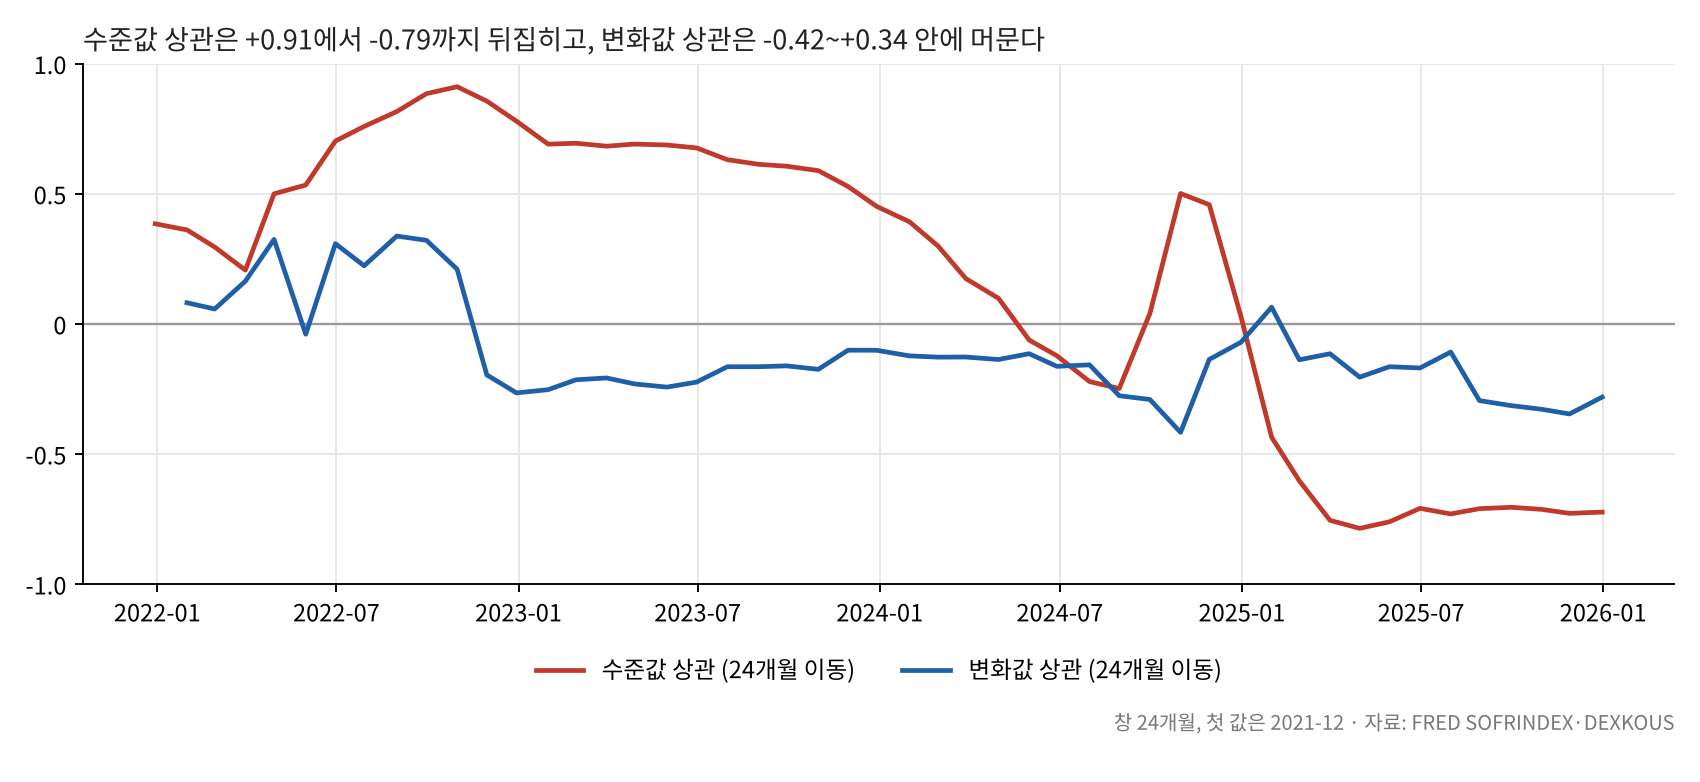

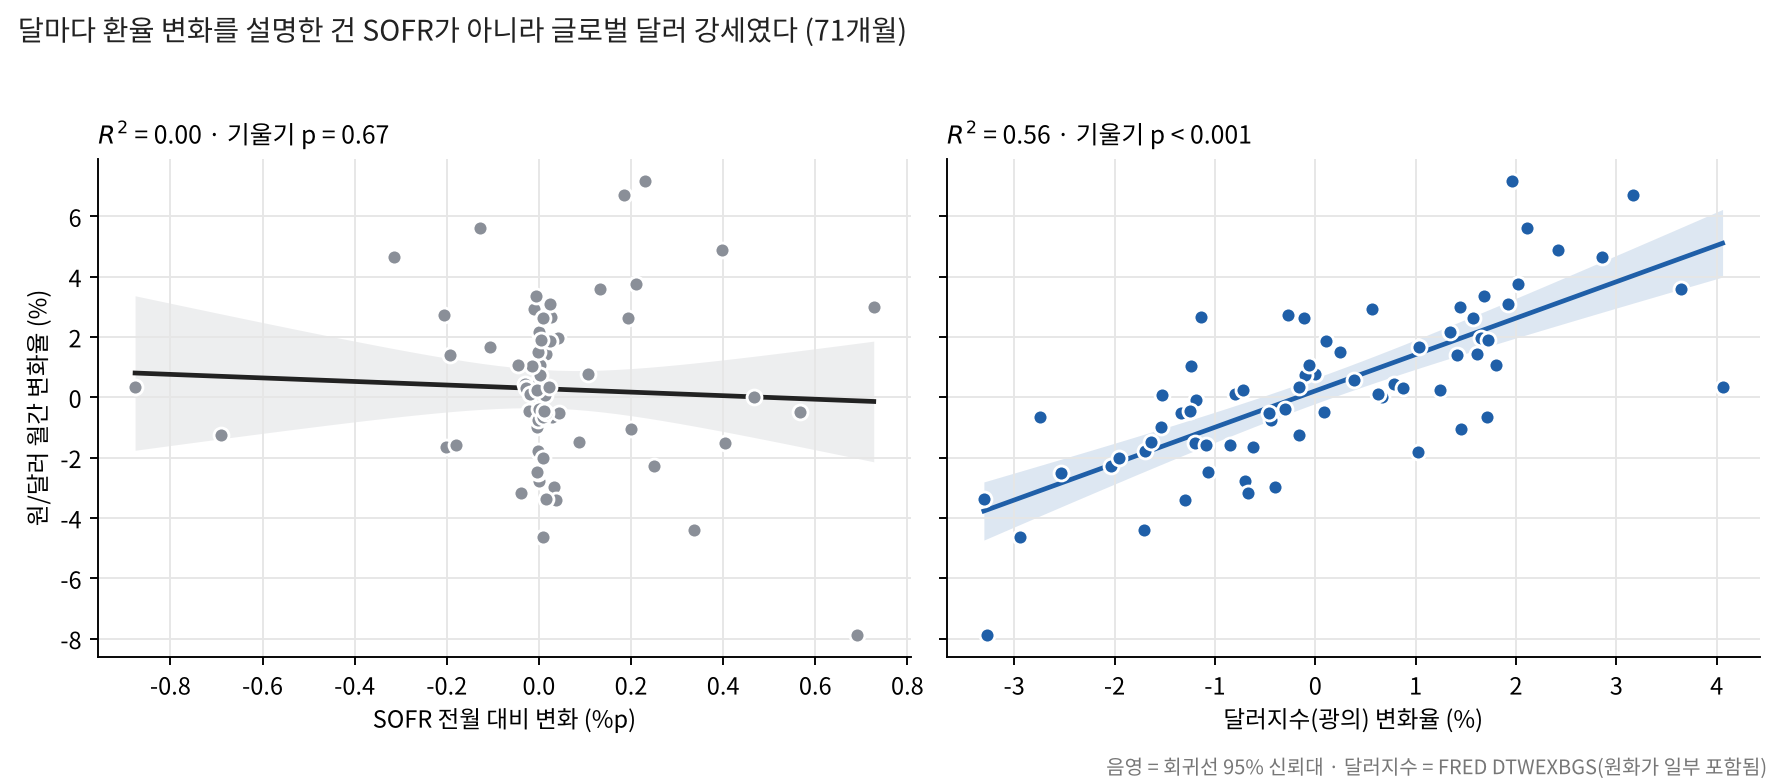

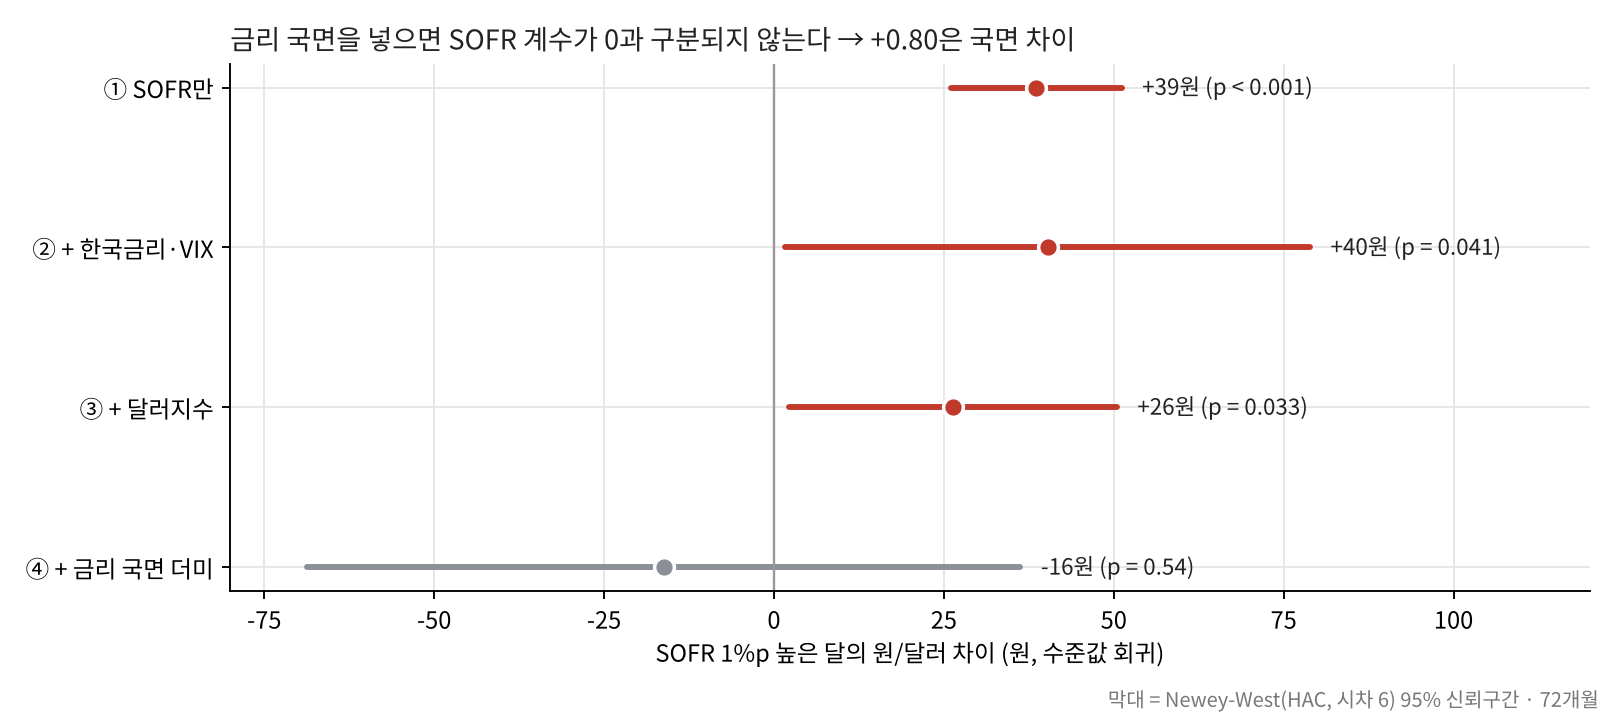

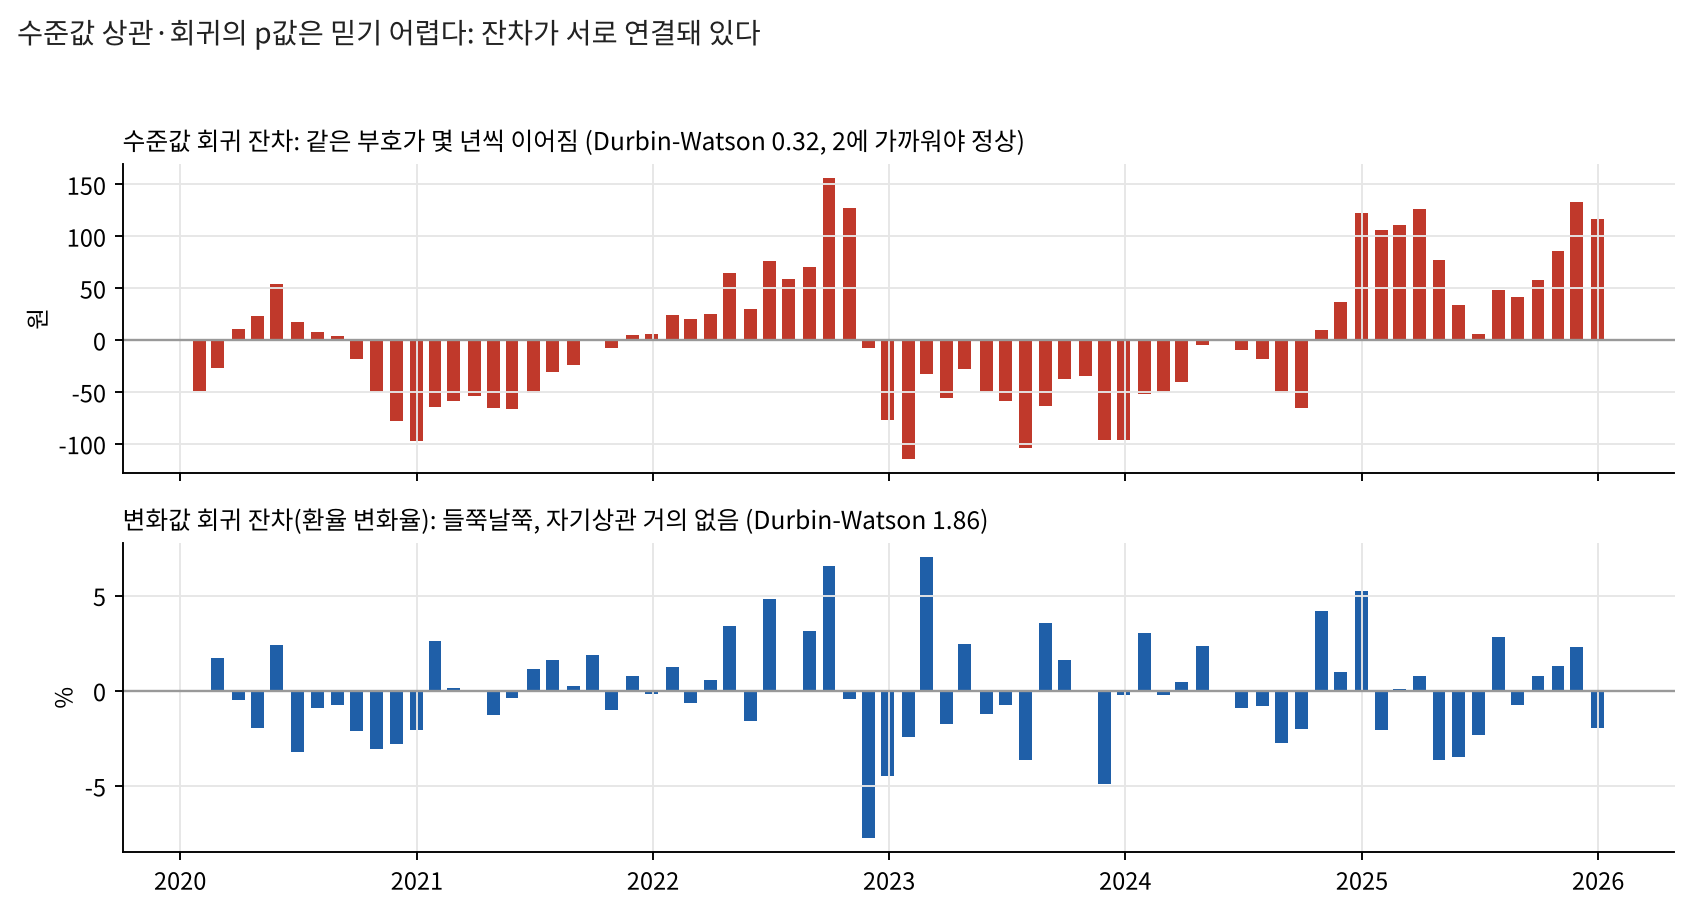

In [9]:
from IPython.display import Image, display
for f in ["rolling_corr", "change_drivers", "coef_ladder", "residual_autocorr"]:
    display(Image(filename=str(RUN / "figures" / f"{f}.png"), width=820))

In [10]:
# 제출본 output/robustness.json과 숫자가 같은지 (실행 시각만 다름)
# 파이썬·numpy 버전에 따라 소수 10자리 아래 계산 오차가 생길 수 있어 상대오차 1e-6 이내면 같다고 본다
import math
sub = json.loads((ROOT / "output/robustness.json").read_text(encoding="utf-8"))
new = json.loads((RUN / "robustness.json").read_text(encoding="utf-8"))
def same(a, b, path=""):
    if isinstance(a, dict):
        return a.keys() == b.keys() and all(same(a[k], b[k], path + "." + k) for k in a if k != "generated_at")
    if isinstance(a, list):
        return len(a) == len(b) and all(same(x, y, path) for x, y in zip(a, b))
    if isinstance(a, float) and isinstance(b, (int, float)):
        return math.isclose(a, b, rel_tol=1e-6, abs_tol=1e-12)
    return a == b
print("제출본과 같음" if same(sub, new) else "다름: 제출 전에 python source/robustness_check.py 를 다시 실행하세요")

제출본과 같음


## 요약
1. **수준값 +0.80은 국면 차이**다. 금리 국면을 고정하면 SOFR 계수가 0과 구분되지 않고, 두 수준값은 비정상이며 공적분이 없어 p값이 과장된다.
2. **월별 변화로는 금리와 환율이 따로 움직였다.** 변화값 r = -0.05 (p = 0.67, 95% CI -0.28~+0.18). 순위상관·2020-03 제외·통제변수·시차·그레인저 어디서도 같다.
3. **환율 변화는 글로벌 달러 강세와 함께 움직였다.** 달러지수 변화 하나로 월별 환율 변화의 56%가 설명되고(통제변수를 모두 넣으면 57%), SOFR 변화는 0.3%다.
4. **이자 증가분의 72%는 금리**다. 분해 방식을 바꿔도 72%, 시작 달을 바꾸면 72~81%라 72%는 보수적인 값이다.
5. 참고로만 쓸 숫자: 기간 분할 -0.56(블록 부트스트랩 구간이 0 포함), 저금리 덩어리 +0.45(BH 보정 후 유의하지 않음), 환율 우세 44/71(p = 0.057).